  FARM_ID CROP_TYPE  YIELD_KG  AREA_ACRES HARVEST_DATE    DISTRICT SEASON  \
0    F001     Wheat    1500.0         4.0   01/01/2023     Sialkot   Rabi   
1    F002     Wheat    1500.0         5.0   02/01/2023      Multan   Rabi   
2    F003     Wheat    2500.0         5.0   03/01/2023  Faisalabad   Rabi   
3    F004     Wheat    1500.0         NaN   04/01/2023      Multan   Rabi   
4    F005      Rice    1500.0         4.0   05/01/2023  Faisalabad   Rabi   
5    F006      Rice    2000.0         6.0   06/01/2023  Faisalabad   Rabi   
6    F007     Maize    1500.0         6.0   07/01/2023  Faisalabad   Rabi   
7    F008     Wheat    1500.0         5.0   08/01/2023      Lahore   Rabi   
8    F009     Wheat    2000.0         5.0   09/01/2023  Faisalabad   Rabi   
9    F010     Wheat    1500.0         3.0   10/01/2023  Faisalabad   Rabi   

  FERTILIZER_USED  YIELD_VALUE  
0             Yes        30000  
1              No        30000  
2             Yes        50000  
3             Yes   

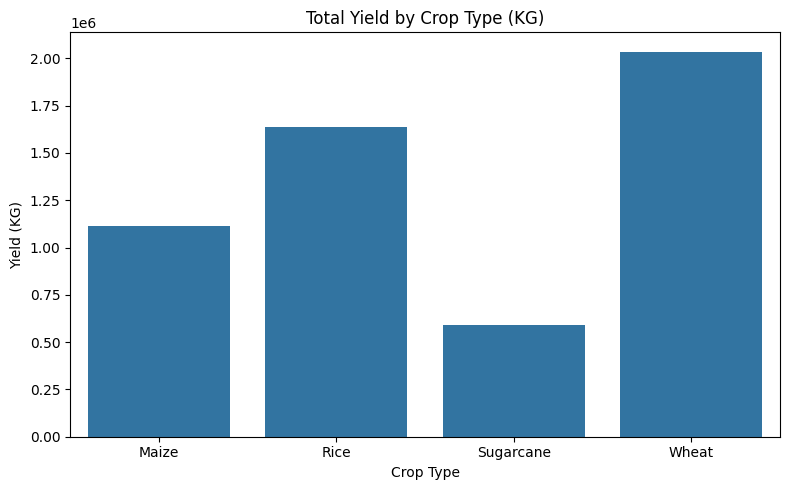

              YIELD_KG
HARVEST_DATE          
2023-01-01      1500.0
2023-01-02      1500.0
2023-01-03      2500.0
2023-01-04      1500.0
2023-01-05      1500.0
...                ...
2031-03-15      1500.0
2031-03-16      2000.0
2031-03-17      2000.0
2031-03-18      2000.0
2031-03-19      2500.0

[2670 rows x 1 columns]


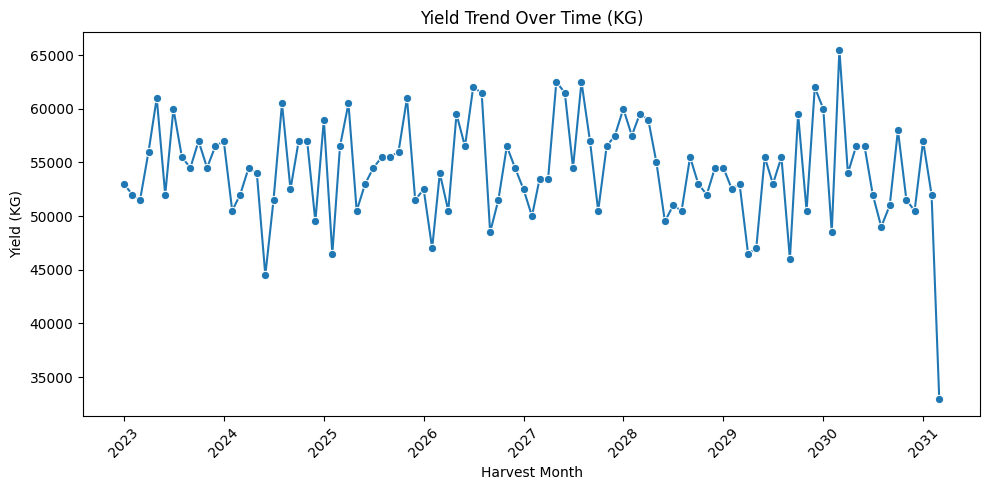

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Question 1: Load the crop-yield dataset
crop_df = pd.read_csv("crop_yield.csv")

# Question 2: Display the first ten records
print(crop_df.head(10))

# Question 3: Count missing values in each column
print(crop_df.isnull().sum())

# Question 4: Check the data type of every column
print(crop_df.dtypes)

# Question 5: Generate descriptive statistics for numeric columns
print(crop_df.describe())

# Question 6: Summarize the non-numeric columns
print(crop_df.describe(exclude="number"))

# Question 7: Remove rows where the yield amount is missing
crop_df = crop_df.dropna(subset=["YIELD_KG"])

# Question 8: Replace missing area values with the column average
crop_df["AREA_ACRES"] = crop_df["AREA_ACRES"].fillna(crop_df["AREA_ACRES"].mean())

# Question 9: Fill unavailable district entries with 'Unknown'
crop_df["DISTRICT"] = crop_df["DISTRICT"].fillna("Unknown")

# Question 1: Load the crop-yield dataset0
crop_df["FERTILIZER_USED"] = crop_df["FERTILIZER_USED"].fillna("No")

# Question 1: Load the crop-yield dataset1
crop_df["YIELD_VALUE"] = crop_df["YIELD_VALUE"].fillna(crop_df["YIELD_VALUE"].mean())

# Question 1: Load the crop-yield dataset2
crop_df["HARVEST_DATE"] = pd.to_datetime(crop_df["HARVEST_DATE"], format="%d/%m/%Y", errors="coerce")

# Question 1: Load the crop-yield dataset3
crop_df["FARM_ID"] = crop_df["FARM_ID"].str.replace("F", "").astype(int)

# Question 14: Review missing-value counts after cleaning
print(crop_df.isnull().sum())

# Question 15: Recheck the column data types
print(crop_df.dtypes)

# Question 16: Calculate the combined yield for each crop category
yield_by_crop = crop_df.groupby("CROP_TYPE", as_index=False).agg({"YIELD_KG": "sum"})
print(yield_by_crop)

# Question 1: Load the crop-yield dataset7
plt.figure(figsize=(8, 5))
sns.barplot(data=yield_by_crop, x="CROP_TYPE", y="YIELD_KG")
plt.title("Total Yield by Crop Type (KG)")
plt.xlabel("Crop Type")
plt.ylabel("Yield (KG)")
plt.tight_layout()
plt.show()

# Question 1: Load the crop-yield dataset8
yield_pivot = crop_df.pivot_table(values="YIELD_KG", index="HARVEST_DATE", aggfunc="sum")
print(yield_pivot)
monthly_yield = yield_pivot.resample("MS").sum()
plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_yield, x=monthly_yield.index, y="YIELD_KG", marker="o")
plt.title("Yield Trend Over Time (KG)")
plt.xlabel("Harvest Month")
plt.ylabel("Yield (KG)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("crop_yield_trend.png")
plt.show()